# ДЗ 2. Проєктування бази даних для ML-сценарію

**Сценарій:** прогнозування покупки в e-commerce. Модель передбачає, чи зробить клієнт оплачене замовлення протягом 30 днів після `prediction_ts`.

**Сутності домену:** клієнти, товари, замовлення, позиції замовлень. Природний зв'язок N:M між замовленнями й товарами реалізовано bridge-таблицею `hw2_order_items`.

In [ ]:
%pip install -q pgserver psycopg2-binary sqlalchemy

In [ ]:
import pgserver
import pandas as pd
from sqlalchemy import create_engine

srv = pgserver.get_server("/content/pgdata", cleanup_mode=None)
engine = create_engine(srv.get_uri())

def sql(q):
    with engine.begin() as conn:
        res = conn.exec_driver_sql(q)
        if res.returns_rows:
            return pd.DataFrame(res.fetchall(), columns=list(res.keys()))

## Завдання 1. ER-діаграма

Три рівні: бізнесові сутності (синій), offline-рівень feature store з історією ознак і training events (помаранчевий), online-рівень з поточними ознаками (зелений).

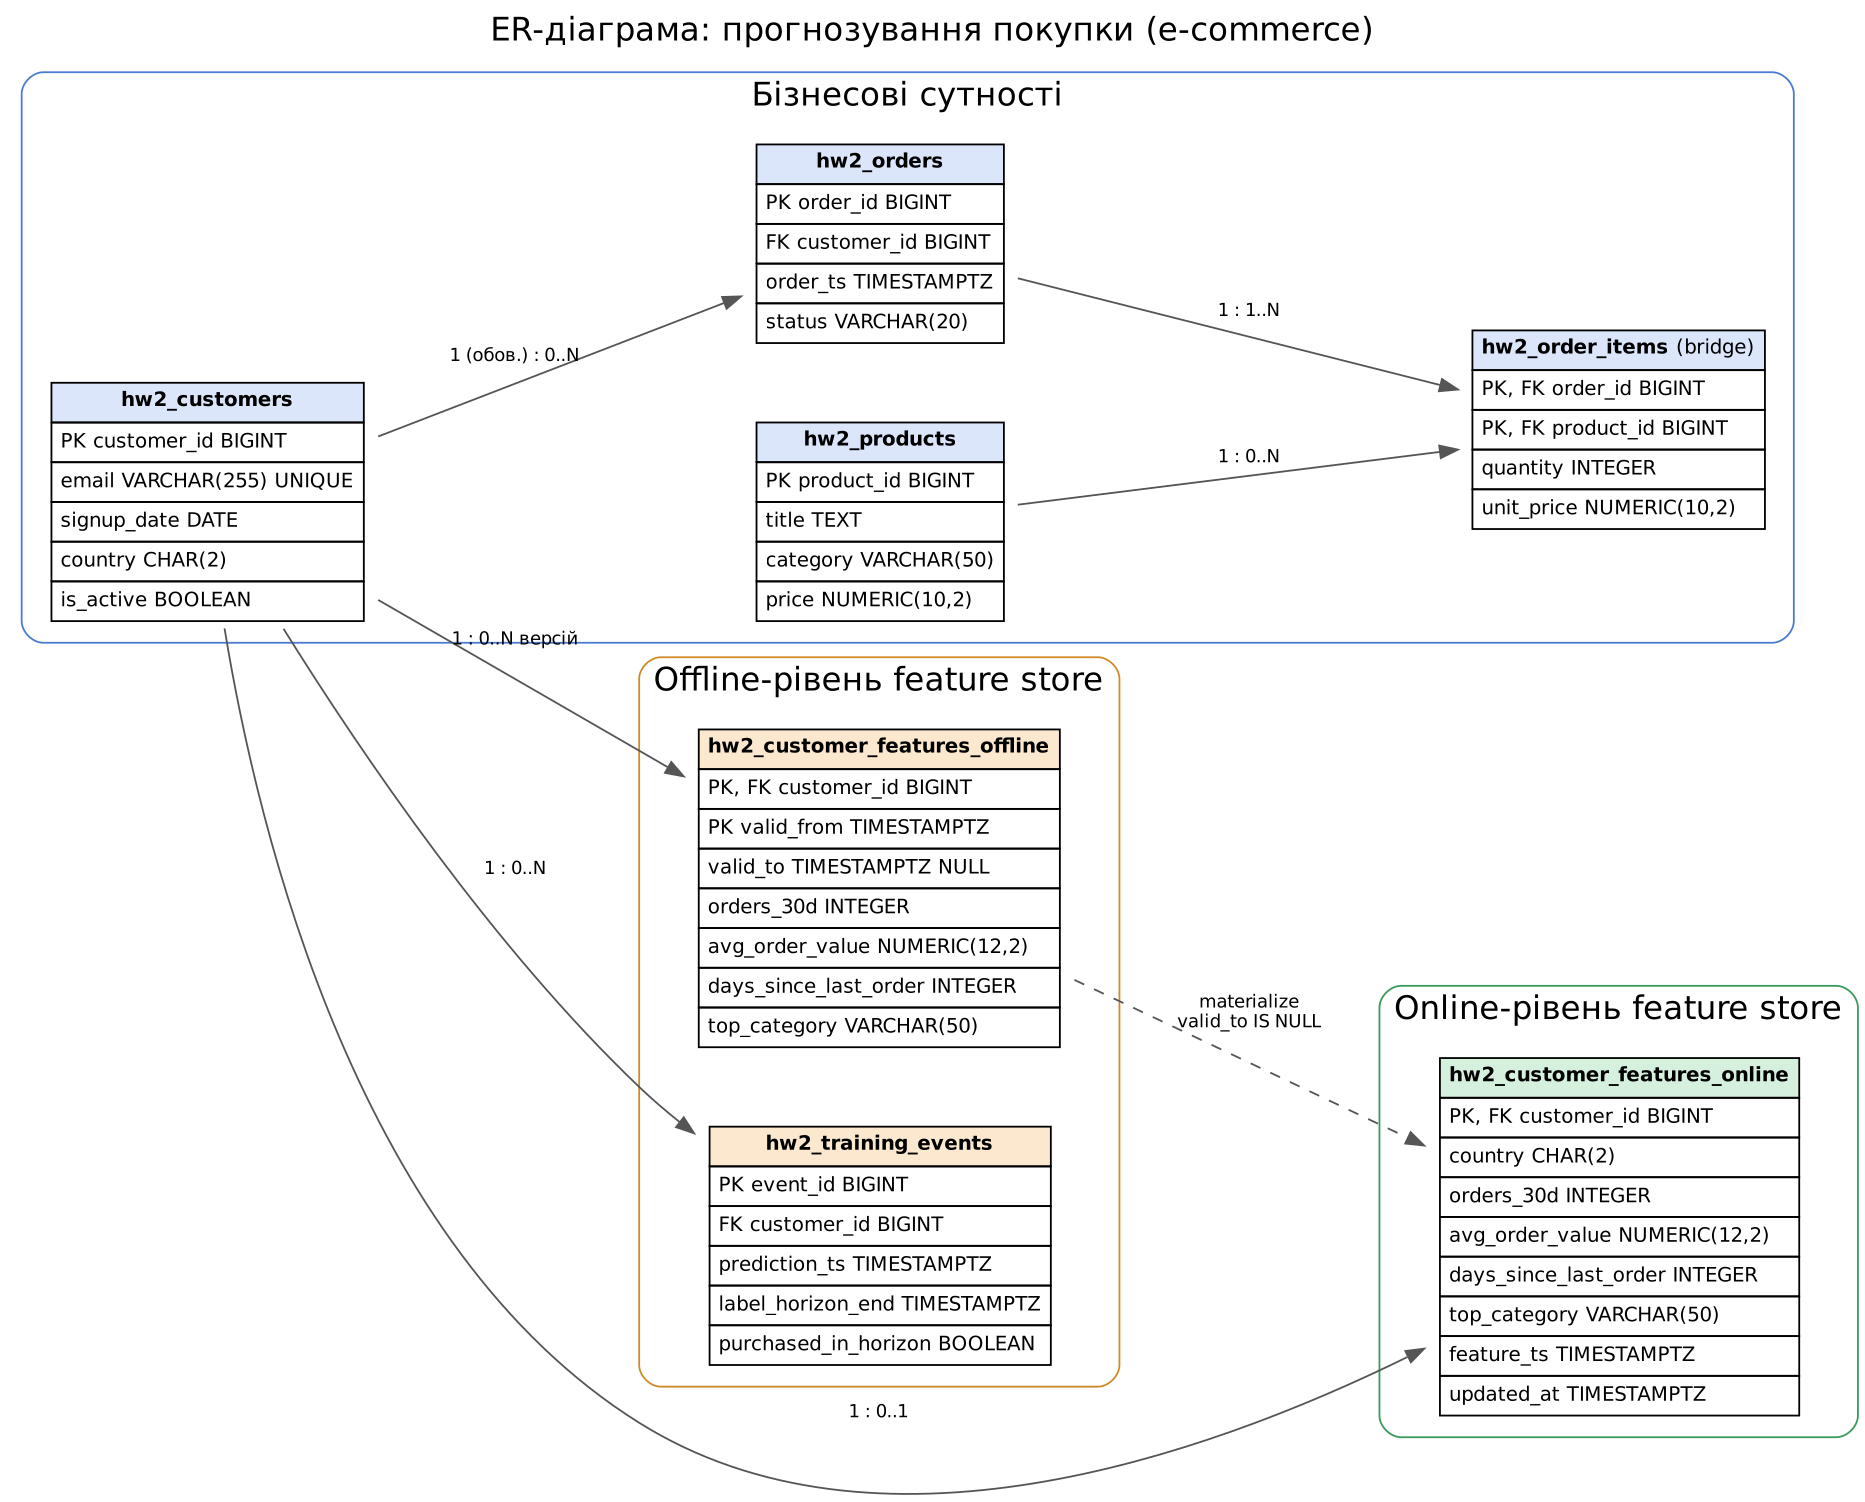

**Кардинальності:**
- `customers 1 — 0..N orders`: замовлення обов'язково має клієнта.
- `orders 1 — 1..N order_items`, `products 1 — 0..N order_items`: N:M через bridge.
- `customers 1 — 0..N customer_features_offline`: кілька версій ознак у часі.
- `customers 1 — 0..N training_events`.
- `customers 1 — 0..1 customer_features_online`: один поточний рядок на клієнта.

## Завдання 2. DDL у PostgreSQL 16

In [ ]:
sql("""
SET TIME ZONE 'UTC';

DROP TABLE IF EXISTS
    hw2_customer_features_online,
    hw2_training_events,
    hw2_customer_features_offline,
    hw2_order_items,
    hw2_orders,
    hw2_products,
    hw2_customers
CASCADE;

CREATE TABLE hw2_customers (
    customer_id BIGINT PRIMARY KEY,
    email VARCHAR(255) NOT NULL UNIQUE,
    signup_date DATE NOT NULL,
    country CHAR(2) NOT NULL,
    is_active BOOLEAN NOT NULL DEFAULT TRUE
);

CREATE TABLE hw2_products (
    product_id BIGINT PRIMARY KEY,
    title TEXT NOT NULL,
    category VARCHAR(50) NOT NULL,
    price NUMERIC(10, 2) NOT NULL CHECK (price > 0)
);

CREATE TABLE hw2_orders (
    order_id BIGINT PRIMARY KEY,
    customer_id BIGINT NOT NULL REFERENCES hw2_customers(customer_id),
    order_ts TIMESTAMPTZ NOT NULL,
    status VARCHAR(20) NOT NULL
        CHECK (status IN ('created', 'paid', 'shipped', 'cancelled'))
);

CREATE TABLE hw2_order_items (
    order_id BIGINT NOT NULL REFERENCES hw2_orders(order_id),
    product_id BIGINT NOT NULL REFERENCES hw2_products(product_id),
    quantity INTEGER NOT NULL CHECK (quantity > 0),
    unit_price NUMERIC(10, 2) NOT NULL CHECK (unit_price >= 0),
    PRIMARY KEY (order_id, product_id)
);

CREATE INDEX hw2_idx_orders_customer_ts
    ON hw2_orders (customer_id, order_ts DESC);

CREATE TABLE hw2_customer_features_offline (
    customer_id BIGINT NOT NULL REFERENCES hw2_customers(customer_id),
    orders_30d INTEGER NOT NULL CHECK (orders_30d >= 0),
    avg_order_value NUMERIC(12, 2)
        CHECK (avg_order_value IS NULL OR avg_order_value >= 0),
    days_since_last_order INTEGER
        CHECK (days_since_last_order IS NULL OR days_since_last_order >= 0),
    top_category VARCHAR(50),
    valid_from TIMESTAMPTZ NOT NULL,
    valid_to TIMESTAMPTZ,
    PRIMARY KEY (customer_id, valid_from),
    CHECK (valid_to IS NULL OR valid_to > valid_from)
);

CREATE INDEX hw2_idx_customer_features_asof
    ON hw2_customer_features_offline (customer_id, valid_from DESC);

CREATE TABLE hw2_training_events (
    event_id BIGINT GENERATED BY DEFAULT AS IDENTITY PRIMARY KEY,
    customer_id BIGINT NOT NULL REFERENCES hw2_customers(customer_id),
    prediction_ts TIMESTAMPTZ NOT NULL,
    label_horizon_end TIMESTAMPTZ NOT NULL,
    purchased_in_horizon BOOLEAN NOT NULL,
    CHECK (label_horizon_end > prediction_ts)
);

CREATE TABLE hw2_customer_features_online (
    customer_id BIGINT PRIMARY KEY REFERENCES hw2_customers(customer_id),
    country CHAR(2) NOT NULL,
    orders_30d INTEGER NOT NULL CHECK (orders_30d >= 0),
    avg_order_value NUMERIC(12, 2)
        CHECK (avg_order_value IS NULL OR avg_order_value >= 0),
    days_since_last_order INTEGER,
    top_category VARCHAR(50),
    feature_ts TIMESTAMPTZ NOT NULL,
    updated_at TIMESTAMPTZ NOT NULL DEFAULT CURRENT_TIMESTAMP
);
""")

## Тестові дані

In [ ]:
sql("""
INSERT INTO hw2_customers (customer_id, email, signup_date, country) VALUES
    (1, 'olena@example.com', DATE '2024-01-10', 'UA'),
    (2, 'piotr@example.com', DATE '2024-02-20', 'PL'),
    (3, 'andrii@example.com', DATE '2024-03-15', 'UA');

INSERT INTO hw2_products (product_id, title, category, price) VALUES
    (10, 'Wireless Mouse', 'electronics', 25.00),
    (11, 'Python Book', 'books', 40.00),
    (12, 'Coffee Beans 1kg', 'grocery', 18.50),
    (13, 'USB-C Hub', 'electronics', 55.00);

INSERT INTO hw2_orders (order_id, customer_id, order_ts, status) VALUES
    (100, 1, TIMESTAMPTZ '2024-10-05 12:00:00+00', 'shipped'),
    (101, 1, TIMESTAMPTZ '2024-11-20 09:30:00+00', 'shipped'),
    (102, 2, TIMESTAMPTZ '2024-10-28 18:15:00+00', 'paid'),
    (103, 3, TIMESTAMPTZ '2024-11-02 08:00:00+00', 'shipped'),
    (104, 3, TIMESTAMPTZ '2024-12-12 14:45:00+00', 'cancelled');

INSERT INTO hw2_order_items (order_id, product_id, quantity, unit_price) VALUES
    (100, 10, 1, 25.00),
    (100, 12, 2, 18.50),
    (101, 11, 1, 40.00),
    (102, 13, 1, 55.00),
    (103, 12, 3, 18.50),
    (104, 10, 1, 25.00);

INSERT INTO hw2_customer_features_offline
    (customer_id, orders_30d, avg_order_value, days_since_last_order, top_category, valid_from, valid_to)
VALUES
    (1, 0, NULL,   NULL, NULL,          TIMESTAMPTZ '2024-10-01 00:00:00+00', TIMESTAMPTZ '2024-10-06 00:00:00+00'),
    (1, 1, 62.00,  1,    'grocery',     TIMESTAMPTZ '2024-10-06 00:00:00+00', TIMESTAMPTZ '2024-11-05 00:00:00+00'),
    (1, 0, 62.00,  31,   'grocery',     TIMESTAMPTZ '2024-11-05 00:00:00+00', TIMESTAMPTZ '2024-11-21 00:00:00+00'),
    (1, 1, 40.00,  1,    'books',       TIMESTAMPTZ '2024-11-21 00:00:00+00', NULL),
    (2, 0, NULL,   NULL, NULL,          TIMESTAMPTZ '2024-10-01 00:00:00+00', TIMESTAMPTZ '2024-10-29 00:00:00+00'),
    (2, 1, 55.00,  1,    'electronics', TIMESTAMPTZ '2024-10-29 00:00:00+00', TIMESTAMPTZ '2024-11-28 00:00:00+00'),
    (2, 0, 55.00,  31,   'electronics', TIMESTAMPTZ '2024-11-28 00:00:00+00', NULL),
    (3, 0, NULL,   NULL, NULL,          TIMESTAMPTZ '2024-10-01 00:00:00+00', TIMESTAMPTZ '2024-11-03 00:00:00+00'),
    (3, 1, 55.50,  1,    'grocery',     TIMESTAMPTZ '2024-11-03 00:00:00+00', TIMESTAMPTZ '2024-12-03 00:00:00+00'),
    (3, 0, 55.50,  31,   'grocery',     TIMESTAMPTZ '2024-12-03 00:00:00+00', NULL);

INSERT INTO hw2_training_events
    (customer_id, prediction_ts, label_horizon_end, purchased_in_horizon)
VALUES
    (1, TIMESTAMPTZ '2024-10-15 10:00:00+00', TIMESTAMPTZ '2024-11-14 10:00:00+00', FALSE),
    (1, TIMESTAMPTZ '2024-11-10 10:00:00+00', TIMESTAMPTZ '2024-12-10 10:00:00+00', TRUE),
    (2, TIMESTAMPTZ '2024-11-15 10:00:00+00', TIMESTAMPTZ '2024-12-15 10:00:00+00', FALSE),
    (3, TIMESTAMPTZ '2024-10-20 10:00:00+00', TIMESTAMPTZ '2024-11-19 10:00:00+00', TRUE),
    (3, TIMESTAMPTZ '2024-12-05 10:00:00+00', TIMESTAMPTZ '2025-01-04 10:00:00+00', FALSE);

INSERT INTO hw2_customer_features_online
    (customer_id, country, orders_30d, avg_order_value, days_since_last_order, top_category, feature_ts)
SELECT f.customer_id, c.country, f.orders_30d, f.avg_order_value,
       f.days_since_last_order, f.top_category, f.valid_from
FROM hw2_customer_features_offline AS f
JOIN hw2_customers AS c ON c.customer_id = f.customer_id
WHERE f.valid_to IS NULL;
""")

In [ ]:
sql("SELECT COUNT(*) AS rows, COUNT(DISTINCT customer_id) AS entities FROM hw2_customer_features_offline")

## Завдання 3. Нормалізація

Бізнесові таблиці `hw2_customers`, `hw2_products`, `hw2_orders`, `hw2_order_items` перебувають у 3НФ. Кожен атрибут атомарний, усі неключові атрибути залежать лише від повного ключа, транзитивних залежностей немає.

Враховані функціональні залежності: `customer_id → email, signup_date, country`; `product_id → title, category, price`; `order_id → customer_id, order_ts, status`; `(order_id, product_id) → quantity, unit_price`. Через останню залежність товари винесено в bridge-таблицю, а не в масив у `orders`. `unit_price` зберігається в позиції, бо ціна товару змінюється, і це окремий факт, а не дублікат `price`.

Категорія товару зберігається лише в `products`, тому зміна категорії оновлює один рядок, а не всі позиції замовлень. Країна зберігається лише в `customers`, а не в кожному замовленні.

Offline-таблиця ознак також у 3НФ: ключ `(customer_id, valid_from)` визначає всі значення версії, і жодна ознака не залежить від іншої неключової ознаки.

Навмисно денормалізована `hw2_customer_features_online`: вона дублює `country` з `customers` і поточні ознаки з offline-таблиці. Read pattern тут один: lookup за `customer_id` під час inference з низькою latency, тому один рядок без JOIN швидший і простіший.

Ризик: дубльовані значення можуть розійтися з джерелом, наприклад якщо клієнт змінить країну. Online-таблиця оновлюється з offline-джерела batch-джобом через `INSERT ... ON CONFLICT (customer_id) DO UPDATE`, беручи версії з `valid_to IS NULL`, а `feature_ts` показує свіжість даних.

## Завдання 4. Point-in-Time correctness

Історична таблиця має 10 версій для трьох клієнтів, для `customer_id = 1` чотири послідовні версії.

**AS-OF SELECT 1.** Ознаки клієнта 1 на `2024-11-10 10:00+00`. Версія від `2024-11-21` ще не існувала, тому не повертається.

In [ ]:
sql("""
SELECT customer_id, orders_30d, avg_order_value, top_category
FROM hw2_customer_features_offline
WHERE customer_id = 1
  AND valid_from <= TIMESTAMPTZ '2024-11-10 10:00:00+00'
  AND (valid_to > TIMESTAMPTZ '2024-11-10 10:00:00+00' OR valid_to IS NULL);
""")

**AS-OF SELECT 2.** Той самий клієнт на `2024-11-25`: повертається поточна версія з `valid_to = NULL`.

In [ ]:
sql("""
SELECT customer_id, orders_30d, avg_order_value, top_category, valid_from, valid_to
FROM hw2_customer_features_offline
WHERE customer_id = 1
  AND valid_from <= TIMESTAMPTZ '2024-11-25 10:00:00+00'
  AND (valid_to > TIMESTAMPTZ '2024-11-25 10:00:00+00' OR valid_to IS NULL);
""")

**AS-OF SELECT 3.** Зріз ознак усіх клієнтів на `2024-11-15`.

In [ ]:
sql("""
SELECT customer_id, orders_30d, avg_order_value, top_category
FROM hw2_customer_features_offline
WHERE valid_from <= TIMESTAMPTZ '2024-11-15 00:00:00+00'
  AND (valid_to > TIMESTAMPTZ '2024-11-15 00:00:00+00' OR valid_to IS NULL)
ORDER BY customer_id;
""")

**AS-OF JOIN для training data.** Кожна подія отримує рівно одну версію ознак, чинну на `prediction_ts`.

In [ ]:
sql("""
SELECT e.event_id, e.customer_id, e.prediction_ts, e.purchased_in_horizon,
       f.orders_30d, f.avg_order_value, f.days_since_last_order, f.top_category
FROM hw2_training_events AS e
LEFT JOIN hw2_customer_features_offline AS f
  ON f.customer_id = e.customer_id
 AND f.valid_from <= e.prediction_ts
 AND (f.valid_to > e.prediction_ts OR f.valid_to IS NULL)
ORDER BY e.event_id;
""")

**Перевірка перекривних інтервалів** (має повернути 0 рядків).

In [ ]:
sql("""
SELECT a.customer_id, a.valid_from AS a_from, a.valid_to AS a_to,
       b.valid_from AS b_from, b.valid_to AS b_to
FROM hw2_customer_features_offline AS a
JOIN hw2_customer_features_offline AS b
  ON a.customer_id = b.customer_id
 AND a.valid_from < COALESCE(b.valid_to, 'infinity'::timestamptz)
 AND b.valid_from < COALESCE(a.valid_to, 'infinity'::timestamptz)
 AND a.valid_from < b.valid_from;
""")

**Наївний JOIN лише за `customer_id`** для порівняння: замість 5 подій отримуємо всі комбінації подій і версій.

In [ ]:
sql("""
SELECT COUNT(*) AS naive_rows FROM hw2_training_events AS e
JOIN hw2_customer_features_offline AS f ON f.customer_id = e.customer_id;
""")

**Пояснення:**

1. `valid_from <= prediction_ts` залишає лише версії, які вже існували на момент прогнозу.
2. `valid_to > prediction_ts OR valid_to IS NULL` відкидає версії, що завершилися до прогнозу, і залишає поточну відкриту версію.
3. Інтервали напіввідкриті `[valid_from, valid_to)`: момент зміни належить лише новій версії. Тоді сусідні версії стикуються без перекриття і без розриву, і на будь-який момент чинна рівно одна.
4. Без часового фільтра до події клієнта 1 від `2024-11-10` приєдналась би версія від `2024-11-21` з `orders_30d = 1` і `top_category = 'books'`. Вона відображає покупку `2024-11-20`, яка і є міткою `purchased_in_horizon = TRUE`. Це data leakage: модель бачить майбутнє, якість на валідації завищена. Крім того, кожна подія дублюється за кількістю версій (17 рядків замість 5).

## Завдання 5. Reflection

**Найскладніше.** Найбільше часу забрала point-in-time correctness. Потрібно було підібрати версії ознак так, щоб інтервали стикувались без перекриттів, а мітки в training events відповідали реальним замовленням у горизонті. Друге за складністю — кардинальності: спершу я хотів зв'язати online-ознаки з offline-таблицею напряму, але FK на композитний ключ з `valid_from` нічого не дає, тому обидва рівні посилаються на `customers`.

**Компроміси.** Бізнесові таблиці нормалізовані до 3НФ, бо в них часто пишуть, і дублювання призвело б до аномалій оновлення. `unit_price` у `order_items` свідомо зберігається окремо від `products.price`, бо фіксує ціну на момент покупки. Online-таблиця денормалізована: вона дублює `country` і поточні ознаки, бо її читають лише за `customer_id`, і для inference важлива latency, а не економія місця. Offline-таблиця залишається історичною й нормалізованою, бо з неї будуються training datasets.

**Швидкий online lookup.** Для великої кількості користувачів я б тримав один попередньо матеріалізований рядок на `entity_id` у key-value сховищі на кшталт Redis або DynamoDB, а PostgreSQL залишив джерелом. Далі: кешування гарячих ключів, шардування за `customer_id`, інкрементальне оновлення з потоку подій замість повного batch-перерахунку, і моніторинг свіжості через `feature_ts` з алертом, якщо дані застаріли.

**Ризики еволюції схеми за шість місяців.** Перейменування `avg_order_value` зламає feature lookup у старій моделі. Зміна типу `customer_id`, наприклад на UUID, розведе ідентифікатори training і inference. Найнебезпечніша зміна семантики: якщо `orders_30d` почне рахувати і скасовані замовлення, назва та тип не зміняться, але модель отримає іншу ознаку. Таку зміну варто оформлювати як `orders_30d_v2`. Видаляти колонки можна лише після перевірки всіх readers, бо старі версії моделей можуть ще працювати в production. Усі зміни я б проводив через версіоновані міграції Alembic.